# 13 — 論文用PPLの統一再評価（2048・各ブロックBOS）

**本番未実行。** Llama/Gemmaを1つずつ選び、元のLRA条件を維持して評価方式を統一します。2048はBOS 1個＋本文2047個。非重複・WikiText-2 raw test・末尾不完全ブロック切捨て。BOS自体は採点せず、最初の本文トークンから採点。BF16、batch1、SDPA、Transformers4.57.6。

## 実験
- baseline（1）
- top50_fullKS / top50_bulkKS: 全体KS順／両端bulkKS順の上位50行列、DEなし／あり（計4）。08/08_2の保存済み行列名・rankを使い、選択やrankを再推定しない。両端bulkKSはDE後・分散1・matched_upper。DE有無で同じ対象だがrankは異なる。
- budget1: 各7モジュールの全ブロックを近似、言語部全体の約1%削減、DE前後で共通rank（14）。08のbudget_0.01計画をそのまま使う。Gemma分母は言語部3,880,263,168。整数丸めにより削減率は1%未満になり得る。
- decile: 全7モジュール×全10群×DE有無（140）。各条件は元重みから独立に開始。最小側が第1群。
- top50_lora: 上記2順序×DE有無の近似済みモデルをそれぞれLoRA学習して評価（4/seed）。LoRAは12と同じWikiText train・1024・BOSなし・1 epoch・全7モジュール。これは従来adapterを未検証で流用する処理ではない。

1モデル・seed1つで163 PPL、両モデル326。11_1の互換Gemma baseline+Q/K40条件を取り込めれば残り285。環境が不一致なら取り込みを見送り再計算する。全行列の単独LRAは含めない。学習→削除／削除→学習の実験は12で別管理。

## 実行手順
1. Colab GPUを接続。必要ならINSTALL_DEPENDENCIES=Trueでセットアップしカーネル再起動。HF_TOKENは入力欄のみ。
2. MODEL_KEYで1モデル、PHASESで実験を選択。まずPHASES=[]でbaseline確認可能。RUN_EXPERIMENTS=Trueで本番セルを実行。
3. 初期化はtoken・plan検査と互換結果の取込のみ。保存先はDrive data/ibis2026_de_lra/paper-ppl-2048-bos-v1/{model}。完了済みはモデル読み込み前にスキップ。
4. 同じ条件で上から再実行すれば続行。PPLの途中ブロックは再開せずその条件を再評価。LoRAは検証済みcheckpoint/adapterから再開。学習と評価を別管理し、評価だけ変更しても学習を繰り返さない。

## 注意・出所
全体KSは08、両端bulkKSは08_2のrank_plan.json。論文Table3の旧表示値をそのまま再現したと仮定せず、保存計画と実削減率を出力して確認する。既存11_1結果はtoken hash・model revision・BF16/batch1・環境・監査済み実装・funcs1 hashとloss整合性を検査。環境不一致を黙って混合しない。
学習は新たに固定したLoRA条件で行う。従来50行列LoRAのadapterは元の近似重み・学習設定が一致することを確認していないため自動取込しない。旧データとノートブックは変更しない。
SVDは初回計算後Driveとローカルに保存。以降はローカルを使い、再接続時にDriveから検証コピーする。重たい初回SVD/LoRAの本番は作成時未検証。L4で開始可能だがメモリ不足時に精度等を自動変更しない。大型GPUへの切替は必要性を確認して行う。


In [1]:
from pathlib import Path
import os, sys, subprocess, getpass
INSTALL_DEPENDENCIES = True  # 初回に必要な場合のみTrue。torch自体はColabのものを使う。
REPO = next((p for p in [Path.cwd(), *Path.cwd().resolve().parents, Path('/content/RMT_utils'), Path.home()/'GitHub/RMT_utils'] if (p/'funcs1.py').exists()), Path('/content/RMT_utils'))
if not (REPO/'funcs1.py').exists():
    subprocess.run(['git','clone','https://github.com/ryy1210/RMT_utils',str(REPO)],check=True)
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable,'-m','pip','install','-r',str(REPO/'requirements-notebooks.txt'),'transformers==4.57.6'],check=True)
if str(REPO) not in sys.path: sys.path.insert(0,str(REPO))
if not os.environ.get('HF_TOKEN'):
    token=getpass.getpass('HF_TOKEN (ログイン済みなら空欄): ').strip()
    if token: os.environ['HF_TOKEN']=token
print('Repository:',REPO)

# 2026-11-13: paper protocol fixes the Transformers version.
import importlib.metadata
if importlib.metadata.version('transformers')!='4.57.6' or getattr(sys.modules.get('transformers'),'__version__','4.57.6')!='4.57.6':
    raise RuntimeError('INSTALL_DEPENDENCIES=Trueで設定セルを実行し、カーネルを再起動してください: transformers==4.57.6')


Repository: /content/RMT_utils


In [2]:
import json, hashlib, math, gc, time, re, platform, importlib.metadata, inspect, unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
import funcs1
from funcs1 import _dyson_from_svd
if Path('/content').exists():
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT=Path('/content/drive/MyDrive/TUS/hashiguchi/data')
else:
    found=list((Path.home()/'Library/CloudStorage').glob('GoogleDrive-*/*/TUS/hashiguchi/data'))
    if len(found)!=1: raise RuntimeError('DATA_ROOTを手動設定してください: '+str(found))
    DATA_ROOT=found[0]
MODEL_KEY='gemma'  # 'llama' または 'gemma'。必ず1モデルずつ実行する。
OUTPUT_ROOT=DATA_ROOT/'ibis2026_de_lra'/'paper-ppl-2048-bos-v1'
OUTPUT=OUTPUT_ROOT/MODEL_KEY
LEGACY_OUTPUT=DATA_ROOT/'ibis2026_de_lra'/'ibis2026-de-controlled-v2-bulk-order'
MODELS={'llama':'meta-llama/Llama-3.2-3B','gemma':'google/gemma-3-4b-pt'}
RUN_MODELS=[MODEL_KEY]  # 内部用。通常はMODEL_KEYだけ変更する。
SEEDS=[42]  # 論文用の反復は例 [42,43,44]。seed別に保存される。
PHASES=['top50_fullKS','top50_bulkKS','budget1','decile','top50_lora']
ALL_GROUPS={'UP':['up_proj'],'DOWN':['down_proj'],'GATE':['gate_proj'],'Q':['q_proj'],'K':['k_proj'],'V':['v_proj'],'O':['o_proj']}
DECILES=list(range(1,11))  # 全10群。1が最小、10が最大。
REVISIONS={'llama':'13afe5124825b4f3751f836b40dafda64c1ed062','gemma':'cc012e0a6d0787b4adcc0fa2c4da74402494554d'}
TOTAL={'llama':3212749824,'gemma':3880263168}
TRAIN_SEQ_LEN=1024; EVAL_SEQ_LEN=2048; BATCH_SIZE=1; SVD_DEVICE='cuda'; TRAIN_BF16=True
TRAIN=dict(epochs=1,learning_rate=2e-4,batch=1,accumulation=8,rank=8,alpha=16,dropout=0.05,
           warmup_ratio=0.0,save_steps=100,logging_steps=10)
# 既存06と同じ基本LoRA条件。全7モジュールを学習。テストPPLで調整しない。
LOCAL_CACHE=Path('/content/rmt13_cache') if Path('/content').exists() else Path('/tmp/rmt13_cache')
CACHE_ROOT=LOCAL_CACHE
DELETE_CACHE_AFTER_GROUP=True
RUN_EXPERIMENTS=True  # 設定・軽量検証を確認後Trueにして本番セルを実行
AUTO_DISCONNECT=False  # Colab Pro+で長時間実行する場合はTrueにすると便利。FalseでもOK。
ALL_REQUESTED_COMPLETED=False

# 評価だけ変更。学習は従来どおり1024・BOSなし・固定epoch。
TRAIN_TARGET_MODULES=['up_proj','down_proj','gate_proj','q_proj','k_proj','v_proj','o_proj']
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False

GROUPS=dict(ALL_GROUPS)  # 例 {'UP':['up_proj'],'Q':['q_proj']}。LoRAの学習対象は全7種で固定。
IMPORT_11_1=True
PLAN=[]


Mounted at /content/drive


## 共通処理・学習・再開

In [3]:
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def digest(x): return hashlib.sha256(json.dumps(x,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def write_json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix('.tmp');tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False,default=paper_json_default));tmp.replace(path)

def safe_exp(x): return math.exp(x) if x<709 else float('inf')

def atomic_csv(path,df):
    tmp=path.with_suffix('.tmp.csv');df.to_csv(tmp,index=False);tmp.replace(path)

def decompose(weight):
    transposed=weight.shape[0]>weight.shape[1]
    w=(weight.T if transposed else weight).float().to(SVD_DEVICE)
    u,s,v=torch.linalg.svd(w,full_matrices=False)
    # 既存DEと同じ推定式。GPU thin SVD結果をfloat64で渡す。
    y,x,z=_dyson_from_svd(w.cpu().double().numpy(),u.cpu().double().numpy(),s.cpu().double().numpy(),v.cpu().double().numpy())
    ud,sd,vd=torch.linalg.svd(torch.as_tensor(y,device=SVD_DEVICE,dtype=torch.float32),full_matrices=False)
    return {False:(u,s,v,None,None,transposed),True:(ud,sd,vd,x,z,transposed)}

def reconstruct(parts,indices):
    u,s,v,x,z,t=parts
    idx=torch.as_tensor(indices,device=s.device,dtype=torch.long)
    result=(u[:,idx]*s[idx])@v[idx,:]
    if x is not None:
        result*=torch.as_tensor(np.sqrt(x),device=result.device,dtype=result.dtype)[:,None]
        result*=torch.as_tensor(np.sqrt(z),device=result.device,dtype=result.dtype)[None,:]
    if t: result=result.T
    if not torch.isfinite(result).all(): raise FloatingPointError('Nonfinite reconstruction')
    return result

def check_loading_info(info):
    if not isinstance(info,dict): raise RuntimeError('Loading report missing')
    errors={k:info.get(k) for k in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs'] if info.get(k)}
    if errors: raise RuntimeError(f'Pretrained checkpoint did not load completely: {errors}')

def extract_gemma_text(full):
    from transformers import Gemma3ForCausalLM
    # 正式クラスでロードした実Tensorを共有。meta上の空モデルへ全モジュールを置換する。
    decoder=full.model.language_model
    with torch.device('meta'):
        text=Gemma3ForCausalLM(full.config.text_config)
    text.model=decoder
    text.lm_head=full.lm_head
    text.generation_config=full.generation_config
    if any(p.is_meta for p in text.parameters()) or any(b.is_meta for b in text.buffers()):
        raise RuntimeError('Unloaded meta tensors remain')
    return text

def model_load(key):
    kwargs=dict(revision=REVISIONS[key],token=os.environ.get('HF_TOKEN'),torch_dtype=torch.bfloat16,
                low_cpu_mem_usage=True,output_loading_info=True,attn_implementation='sdpa')
    if key=='gemma':
        from transformers import Gemma3ForConditionalGeneration
        # 修正: checkpointのarchitectureと一致するクラスを使う。text_configだけを渡さない。
        full,info=Gemma3ForConditionalGeneration.from_pretrained(MODELS[key],**kwargs)
        check_loading_info(info)
        model=extract_gemma_text(full)
        del full; gc.collect()
    else:
        model,info=AutoModelForCausalLM.from_pretrained(MODELS[key],**kwargs)
        check_loading_info(info)
    actual=sum(p.numel() for p in model.parameters())
    if actual!=TOTAL[key]: raise ValueError(f'Parameter count mismatch {actual} != {TOTAL[key]}')
    if any(p.is_meta for p in model.parameters()): raise RuntimeError('Unloaded model parameters')
    root=result_root(key); root.mkdir(parents=True,exist_ok=True)
    write_json(root/'loading_report.json',dict(model=MODELS[key],revision=REVISIONS[key],
        loader_version=GEMMA_LOADER_VERSION if key=='gemma' else 'auto_verified_v2',
        transformers=importlib.metadata.version('transformers'),parameter_count=actual,
        missing_keys=[],unexpected_keys=[],mismatched_keys=[],config_hash=CONFIG_HASH))
    model.eval(); model.config.use_cache=False
    return model.to('cuda')

def evaluate(model,tokens):
    model.eval()
    losses=[]; counts=[]
    for start in range(0,len(tokens),BATCH_SIZE):
        ids=torch.as_tensor(tokens[start:start+BATCH_SIZE],device=next(model.parameters()).device)
        logits=model(input_ids=ids,use_cache=False).logits
        sums=torch.zeros(ids.shape[0],device=ids.device,dtype=torch.float64)
        for pos in range(0,ids.shape[1]-1,64):
            end=min(pos+64,ids.shape[1]-1)
            loss=F.cross_entropy(logits[:,pos:end].float().transpose(1,2),ids[:,pos+1:end+1],reduction='none')
            if not torch.isfinite(loss).all(): raise FloatingPointError('Nonfinite NLL')
            sums+=loss.double().sum(1)
        losses.extend(sums.cpu().tolist()); counts.extend([ids.shape[1]-1]*ids.shape[0]); del logits
        if start==0 or (start+1)%25==0 or start+1==len(tokens): print(f'  PPL blocks {start+1}/{len(tokens)}',flush=True)
    return np.asarray(losses),np.asarray(counts)

def resolve(model,name):
    found=[m for k,m in model.named_modules() if isinstance(m,torch.nn.Linear) and (k==name or k.endswith('.'+name))]
    if len(found)!=1: raise ValueError(f'Ambiguous module {name}')
    return found[0]

def function_fingerprint(f):
    # ipykernelの一時filename・セル番号は再起動で変わるのでhashに含めない。
    import types
    def normalize(code):
        return [code.co_code.hex(),code.co_names,code.co_varnames,
                [normalize(x) if isinstance(x,types.CodeType) else repr(x) for x in code.co_consts]]
    return digest(normalize(inspect.unwrap(f).__code__))

def read_result(path):
    path=evaluation_dir(path)  # 旧評価・新評価を混ぜない。学習の保存先は変えない。
    if not (path/'summary.json').exists(): return None
    obj=json.loads((path/'summary.json').read_text())
    assert obj['config_hash']==CONFIG_HASH
    f=path/'losses.npz'
    assert sha(f)==obj['loss_hash'], 'Result checksum mismatch'
    with np.load(f) as z: loss=z['loss'];count=z['count']
    assert len(loss)==len(TOKENS[obj['model']]) and np.all(count==EVAL_SEQ_LEN-1) and np.isfinite(loss).all()
    assert obj['eval_hash']==EVAL_HASH
    v=safe_exp(float(loss.sum()/count.sum()))
    assert (None if not np.isfinite(v) else v)==obj['ppl'], 'PPL mismatch'
    return obj

def save_result(path,key,loss,count,extra):
    path=evaluation_dir(path)
    path.mkdir(parents=True,exist_ok=True)
    with open(path/'losses.tmp','wb') as f: np.savez_compressed(f,loss=loss,count=count)
    (path/'losses.tmp').replace(path/'losses.npz')
    value=safe_exp(float(loss.sum()/count.sum()))
    obj=dict(model=key,config_hash=CONFIG_HASH,eval_hash=EVAL_HASH,protocol=PAPER_PROTOCOL,ppl=value if np.isfinite(value) else None,
             ppl_overflow=not np.isfinite(value),loss_hash=sha(path/'losses.npz'),**extra)
    write_json(path/'summary.json',obj)
    return obj

def decile_indices(p,decile):
    if p<10 or decile not in DECILES:raise ValueError('Need p>=10 and decile 1..10')
    # torch.linalg.svdは降順。最小側から順に群を割り当てる。
    return np.array_split(np.arange(p-1,-1,-1),10)[decile-1]

def remove_decile(original,parts,decile):
    idx=decile_indices(len(parts[1]),decile)
    removed=reconstruct(parts,idx)
    value=original.to(device=removed.device,dtype=torch.float32)-removed
    if not torch.isfinite(value).all():raise FloatingPointError('Nonfinite pruned weight')
    return value,idx

def cache_path(key,group,name):
    return CACHE_ROOT/CONFIG_HASH/key/group/(digest(name)[:24]+'.pt')

def prepare_svd_cache(key,group,matrices):
    import shutil
    root=CACHE_ROOT/CONFIG_HASH/key/group;root.mkdir(parents=True,exist_ok=True)
    required=sum(2*4*(min(m.weight.shape)*(sum(m.weight.shape)+1)+sum(m.weight.shape)) for _,m in matrices)
    existing=sum(p.stat().st_size for p in root.glob('*.pt'))
    if shutil.disk_usage(root).free < max(0,required-existing)+1024**3:
        raise RuntimeError(f'SVD cache requires about {required/1e9:.1f} GB; insufficient free disk')
    for i,(name,module) in enumerate(matrices):
        path=cache_path(key,group,name);receipt=path.with_suffix('.json')
        if path.exists() and receipt.exists():
            obj=json.loads(receipt.read_text())
            assert obj['config_hash']==CONFIG_HASH and obj['name']==name and obj['sha256']==sha(path)
            assert obj['shape']==list(module.weight.shape)
            continue
        print(f'{key} {group} SVD {i+1}/{len(matrices)}: {name}',flush=True)
        original=module.weight.detach().cpu().clone();parts=decompose(original)
        stored={}
        for de,(u,s,v,x,z,t) in parts.items():
            stored[de]=(u.cpu(),s.cpu(),v.cpu(),None if x is None else torch.as_tensor(np.asarray(x).copy()),
                        None if z is None else torch.as_tensor(np.asarray(z).copy()),t)
        tmp=path.with_suffix('.tmp');torch.save(stored,tmp);tmp.replace(path)
        write_json(receipt,dict(config_hash=CONFIG_HASH,name=name,shape=list(original.shape),sha256=sha(path)))
        del original,parts,stored;gc.collect();torch.cuda.empty_cache()
    return root

def load_parts(path,de,device):
    obj=torch.load(path,map_location='cpu',weights_only=True)
    u,s,v,x,z,t=obj[de]
    return u.to(device),s.to(device),v.to(device),None if x is None else x.numpy(),None if z is None else z.numpy(),t

def validate_group(model,targets):
    matrices=[(n,m) for n,m in model.named_modules() if isinstance(m,torch.nn.Linear) and n.split('.')[-1] in targets]
    for target in targets:
        names=[n for n,m in matrices if n.split('.')[-1]==target]
        blocks=[int(re.search(r'layers\.(\d+)\.',n).group(1)) for n in names]
        assert sorted(blocks)==list(range(model.config.num_hidden_layers)), f'Incomplete module: {target}'
    return matrices

def smoke_test():
    global SVD_DEVICE
    old=SVD_DEVICE;SVD_DEVICE='cpu'
    try:
        torch.manual_seed(17)
        for shape in [(24,80),(80,24),(24,24)]:
            w=torch.randn(*shape);parts=decompose(w);p=min(shape)
            bins=[decile_indices(p,d) for d in DECILES]
            assert np.array_equal(np.sort(np.concatenate(bins)),np.arange(p))
            assert max(map(len,bins))-min(map(len,bins))<=1
            assert bins[0][0]==p-1 and bins[-1][-1]==0
            for de in [False,True]:
                assert torch.allclose(reconstruct(parts[de],np.arange(p)),w,atol=4e-5,rtol=4e-5)
                for d,idx in zip(DECILES,bins):
                    got,removed=remove_decile(w,parts[de],d)
                    expected=reconstruct(parts[de],np.setdiff1d(np.arange(p),idx))
                    assert torch.allclose(got,expected,atol=4e-5,rtol=4e-5)
        print('PASS: 10群分割・逆変換・転置・全20条件の削除式')
    finally:SVD_DEVICE=old

evaluate=torch.inference_mode()(evaluate)
GEMMA_LOADER_VERSION="conditional_verified_v2"
def result_root(key): return OUTPUT


# Shared paper protocol, embedded in notebooks 12 and 13 for uncommitted Colab use.
PAPER_PROTOCOL = dict(version='paper-2048-each-bos-v1', length=2048, bos='each_block',
    packing='one BOS + 2047 text; disjoint; drop incomplete tail', batch=1,
    corpus_revision='b08601e04326c79dfdd32d625aee71d232d685c3', precision='bf16', attention='sdpa')

def pack_paper_tokens(raw, bos_id, length=2048):
    raw=np.asarray(raw,dtype=np.int64)
    if length<2 or bos_id is None: raise ValueError('Invalid BOS/length')
    n=len(raw)//(length-1)
    if not n: raise ValueError('No complete evaluation blocks')
    a=np.empty((n,length),dtype=np.int64);a[:,0]=bos_id
    a[:,1:]=raw[:n*(length-1)].reshape(n,length-1)
    return a,dict(blocks=n,length=length,scored_tokens=n*(length-1),dropped_tokens=len(raw)-n*(length-1),bos_token_id=int(bos_id))

def paper_environment():
    return dict(python=platform.python_version(),versions={k:importlib.metadata.version(k) for k in
        ('torch','transformers','datasets','numpy')},gpu=torch.cuda.get_device_name() if torch.cuda.is_available() else 'cpu',
        cuda=torch.version.cuda,attention='sdpa',tf32=False)

def paper_json_default(x):
    if isinstance(x,(set,frozenset)): return sorted(x,key=repr)
    if isinstance(x,np.generic):return x.item()
    if isinstance(x,np.ndarray):return x.tolist()
    if isinstance(x,(Path,torch.dtype,torch.device)):return str(x)
    raise TypeError(type(x).__name__)

def prepare_paper_inputs(key, data_root, model_id, revision, train_length=None):
    from transformers import AutoTokenizer
    from datasets import load_dataset
    root=data_root/'ibis2026_de_lra/paper-2048-each-bos-inputs-v1';root.mkdir(parents=True,exist_ok=True)
    tok=None; results={}
    for split in (['test','train'] if train_length is not None else ['test']):
        length=2048 if split=='test' else train_length
        identity=dict(model=model_id,revision=revision,split=split,length=length,
            dataset_revision=PAPER_PROTOCOL['corpus_revision'],transformers=importlib.metadata.version('transformers'),
            packing=PAPER_PROTOCOL['packing'] if split=='test' else 'no BOS; disjoint full blocks; drop tail')
        p=root/f'{key}_{split}_{digest(identity)[:16]}.npy';receipt=p.with_suffix('.json')
        if p.exists() and receipt.exists():
            meta=json.loads(receipt.read_text())
            if meta['identity']!=identity or meta['sha256']!=sha(p):raise ValueError('Input cache checksum/identity mismatch')
            a=np.load(p,allow_pickle=False)
        else:
            text_path=root/f'{split}.txt'
            if not text_path.exists():
                old=data_root/'ibis2026_de_lra/gemma-qk-ppl-settings-grid-v1/inputs/wikitext2_test.txt'
                if split=='test' and old.exists():text=old.read_text(encoding='utf-8')
                else:
                    ds=load_dataset('Salesforce/wikitext','wikitext-2-raw-v1',split=split,revision=PAPER_PROTOCOL['corpus_revision'])
                    text='\n\n'.join(ds['text'])
                text_path.write_text(text,encoding='utf-8')
            if split=='test' and sha(text_path)!='696cca6b65a171b0a358a4be6732cdfdf2dd6164a32e20fd70e3c13fc4dfae83':
                raise ValueError('Test corpus differs from audited 11_1')
            if tok is None:tok=AutoTokenizer.from_pretrained(model_id,revision=revision,token=os.environ.get('HF_TOKEN'))
            raw=np.asarray(tok(text_path.read_text(encoding='utf-8'),add_special_tokens=False)['input_ids'],dtype=np.int64)
            if split=='test':a,meta=pack_paper_tokens(raw,tok.bos_token_id,length)
            else:
                a=raw[:len(raw)//length*length].reshape(-1,length).copy()
                if not len(a):raise ValueError('Empty training data')
                meta=dict(blocks=len(a),length=length,dropped_tokens=len(raw)%length)
            with p.with_suffix('.tmp').open('wb') as f:np.save(f,a,allow_pickle=False)
            p.with_suffix('.tmp').replace(p)
            meta.update(identity=identity,sha256=sha(p),text_sha256=sha(text_path));write_json(receipt,meta)
        if a.ndim!=2 or a.shape[1]!=length or not len(a):raise ValueError('Token shape mismatch')
        if split=='test' and not np.all(a[:,0]==meta['bos_token_id']):raise ValueError('BOS missing')
        results[split]=(a,meta)
    return results

def evaluation_identity(token_hashes):
    # Evaluation identity is separate from training: new evaluation never invalidates adapters.
    return digest(dict(protocol=PAPER_PROTOCOL,tokens=token_hashes,environment=paper_environment(),
        evaluate=function_fingerprint(evaluate),pack=function_fingerprint(pack_paper_tokens)))

def evaluation_dir(path):return Path(path)/'evaluations'/EVAL_HASH


In [4]:
from peft import LoraConfig, TaskType, get_peft_model, PeftModel
from transformers import Trainer, TrainingArguments, TrainerCallback, set_seed
from torch.utils.data import Dataset
import shutil
class PackedTokens(Dataset):
    def __init__(self, array): self.array = array
    def __len__(self): return len(self.array)
    def __getitem__(self, i):
        ids = torch.tensor(self.array[i], dtype=torch.long)
        return {'input_ids': ids, 'attention_mask': torch.ones_like(ids), 'labels': ids.clone()}

def snapshot_files(root):
    return {str(p.relative_to(root)): sha(p) for p in sorted(root.rglob('*'))
            if p.is_file() and p.name != 'receipt.json'}

def verify_files(root, receipt):
    for rel, checksum in receipt['files'].items():
        p=root/rel
        if not p.is_file() or sha(p)!=checksum:
            raise RuntimeError(f'Incomplete/corrupt checkpoint: {p}')

def training_receipt(path):
    f=path/'adapter'/'receipt.json'
    if not f.exists(): return None
    obj=json.loads(f.read_text())
    if obj['config_hash']!=CONFIG_HASH: raise ValueError('Training configuration mismatch')
    verify_files(path/'adapter',obj)
    return obj

class CompleteCheckpoint(TrainerCallback):
    def on_save(self, args, state, control, **kwargs):
        root=Path(args.output_dir)/f'checkpoint-{state.global_step}'
        # receiptを最後に書く。転送途中・カーネル切断時のcheckpointを完了扱いしない。
        write_json(root/'receipt.json',dict(config_hash=CONFIG_HASH,step=state.global_step,files=snapshot_files(root)))

def resume_checkpoint(path):
    checkpoints=sorted((path/'trainer').glob('checkpoint-*'),key=lambda p:int(p.name.split('-')[-1]),reverse=True)
    for root in checkpoints:
        receipt=root/'receipt.json'
        if not receipt.exists():
            print('Incomplete checkpoint ignored:',root.name);continue
        obj=json.loads(receipt.read_text())
        if obj['config_hash']!=CONFIG_HASH: raise ValueError('Checkpoint configuration mismatch')
        try: verify_files(root,obj)
        except RuntimeError:
            print('Corrupt checkpoint ignored:',root.name);continue
        return str(root)
    return None

def train_or_merge(model,key,seed,path):
    receipt=training_receipt(path)
    if receipt:
        print('SKIP training / load adapter:',path,flush=True)
        merged=PeftModel.from_pretrained(model,str(path/'adapter'),is_trainable=False).merge_and_unload()
        return merged.eval()
    set_seed(seed)
    model.config.use_cache=False
    model=get_peft_model(model,LoraConfig(task_type=TaskType.CAUSAL_LM,r=TRAIN['rank'],
        lora_alpha=TRAIN['alpha'],lora_dropout=TRAIN['dropout'],bias='none',
        target_modules=TRAIN_TARGET_MODULES))
    trainable=sum(p.numel() for p in model.parameters() if p.requires_grad)
    if trainable<=0: raise RuntimeError('No trainable LoRA parameters')
    print('LoRA trainable parameters:',trainable,flush=True)
    model.enable_input_require_grads()
    args=TrainingArguments(output_dir=str(path/'trainer'),num_train_epochs=TRAIN['epochs'],
        learning_rate=TRAIN['learning_rate'],per_device_train_batch_size=TRAIN['batch'],
        gradient_accumulation_steps=TRAIN['accumulation'],warmup_ratio=TRAIN['warmup_ratio'],
        lr_scheduler_type='linear',weight_decay=0.0,optim='adamw_torch',bf16=TRAIN_BF16,
        fp16=False,use_cpu=not TRAIN_BF16,gradient_checkpointing=True,gradient_checkpointing_kwargs={'use_reentrant':False},
        save_strategy='steps',save_steps=TRAIN['save_steps'],save_total_limit=2,
        logging_steps=TRAIN['logging_steps'],report_to='none',dataloader_num_workers=0,
        dataloader_pin_memory=TRAIN_BF16,seed=seed,data_seed=seed,remove_unused_columns=False)
    trainer=Trainer(model=model,args=args,train_dataset=PackedTokens(TRAIN_TOKENS[key]),callbacks=[CompleteCheckpoint()])
    trainer.train(resume_from_checkpoint=resume_checkpoint(path))
    # Adapterのみを保存。学習→削除ではmerge後の実重みからSVD/DEを再計算する。
    temporary=path/'adapter.tmp'
    if temporary.exists(): shutil.rmtree(temporary)
    trainer.model.save_pretrained(temporary,safe_serialization=True)
    write_json(temporary/'receipt.json',dict(config_hash=CONFIG_HASH,seed=seed,
        trainable=trainable,global_step=trainer.state.global_step,files=snapshot_files(temporary)))
    final=path/'adapter'
    if final.exists(): raise RuntimeError(f'Unexpected unfinished adapter: {final}')
    temporary.rename(final)
    merged=trainer.model.merge_and_unload()
    merged.gradient_checkpointing_disable()
    merged.config.use_cache=False
    del trainer
    return merged.eval()

def evaluate_save(model,key,path,extra):
    previous=read_result(path)
    if previous: return previous
    model.eval()
    loss,count=evaluate(model,TOKENS[key])
    return save_result(path,key,loss,count,extra)

def restore_group(model,originals):
    with torch.no_grad():
        for name,weight in originals.items(): resolve(model,name).weight.copy_(weight.to(next(model.parameters()).device))

def release():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

In [5]:
# 13: 保存済みrank計画と新評価方式を分離。学習・既存実験は上書きしない。
def tensor_hash(w):return hashlib.sha256(w.detach().cpu().contiguous().view(torch.uint8).numpy().tobytes()).hexdigest()

def build_plan13(key, source_root):
    a=json.loads((source_root/'ibis2026-de-controlled-v1/rank_plan.json').read_text())
    b=json.loads((source_root/'ibis2026-de-controlled-v2-bulk-order/rank_plan.json').read_text())
    jobs=[dict(id='baseline',kind='baseline')]
    for phase,source in [('top50_fullKS',a),('top50_bulkKS',b),('budget1',a)]:
        chosen=[j for j in source if j['model']==key and
            ((phase=='budget1' and j['experiment']=='E1' and j['variant']=='budget_0.01') or
             (phase!='budget1' and j['experiment']=='E3' and j['step']==50))]
        if len(chosen)!=(14 if phase=='budget1' else 2):raise ValueError(f'Missing/duplicate source plan: {key} {phase}')
        for j in chosen:
            if set(j['names'])!=set(j['ranks']) or len(j['names'])!=len(set(j['names'])):raise ValueError('Invalid matrix/rank plan')
            job=dict(id=f"{phase}__{j['scope']}__de{int(j['use_de'])}",kind=phase,source=j,
                group=j['scope'],de=j['use_de'])
            jobs.append(job)
        for scope in set(j['scope'] for j in chosen):
            pair=[j for j in chosen if j['scope']==scope]
            if len(pair)!=2 or {j['use_de'] for j in pair}!={False,True}:raise ValueError('Missing DE pair')
            if pair[0]['names']!=pair[1]['names']:raise ValueError('Target sets differ across DE')
            if phase=='budget1' and pair[0]['ranks']!=pair[1]['ranks']:raise ValueError('Ranks differ in fixed-budget comparison')
    for group in ALL_GROUPS:
        for de in (False,True):
            for d in range(1,11):jobs.append(dict(id=f'decile__{group}__de{int(de)}__d{d:02}',kind='decile',group=group,de=de,decile=d))
    for j in list(jobs):
        if j['kind'].startswith('top50'):
            for seed in SEEDS:jobs.append(dict(j,id=j['id']+f'__lora_seed{seed}',kind='top50_lora',parent_kind=j['kind'],seed=seed))
    return jobs

def requested13(job):
    if job['kind']=='baseline':return True
    if job['kind'] not in PHASES:return False
    if job['kind'] in ('decile','budget1'):
        group=job['group'] if job['kind']=='decile' else next(k for k,v in ALL_GROUPS.items() if v[0]==job['group'])
        return group in GROUPS
    return True

def path13(job):return OUTPUT/'jobs'/job['id']

def complete13(job):
    obj=read_result(path13(job))
    if obj and obj.get('job')!=job:raise ValueError('Saved job specification mismatch')
    return obj

def cache_parts13(name, weight):
    identity=dict(name=name,original_sha256=tensor_hash(weight),shape=list(weight.shape),revision=REVISIONS[MODEL_KEY],
        funcs1_sha256=sha(Path(funcs1.__file__)),torch=torch.__version__,svd_device=SVD_DEVICE,
        algorithm='11 FP32 thin SVD + float64 _dyson_from_svd + FP32 DE SVD')
    h=digest(identity);local=LOCAL_CACHE/'svd'/f'{h}.pt';disk=OUTPUT/'svd'/f'{h}.pt'
    local.parent.mkdir(parents=True,exist_ok=True);disk.parent.mkdir(parents=True,exist_ok=True)
    if h not in VERIFIED_CACHE:
        if disk.exists() and disk.with_suffix('.json').exists():
            receipt=json.loads(disk.with_suffix('.json').read_text())
            if receipt['identity']!=identity:raise ValueError('SVD identity mismatch')
            print('cache copy / verify:',name,flush=True)
            shutil.copyfile(disk,local)
            if sha(local)!=receipt['sha256']:raise ValueError('Corrupt SVD cache')
        else:
            print('SVD / DE:',name,flush=True)
            parts=decompose(weight)
            stored={de:(u.cpu(),s.cpu(),v.cpu(),None if x is None else torch.as_tensor(np.asarray(x).copy()),
                None if z is None else torch.as_tensor(np.asarray(z).copy()),t) for de,(u,s,v,x,z,t) in parts.items()}
            torch.save(stored,local);tmp=disk.with_suffix('.tmp');shutil.copyfile(local,tmp);tmp.replace(disk)
            write_json(disk.with_suffix('.json'),dict(identity=identity,sha256=sha(local)))
            del parts,stored;release()
        VERIFIED_CACHE.add(h)
    obj=torch.load(local,map_location='cpu',weights_only=True)
    return obj

def apply_job13(model,job):
    originals={};records=[]
    if job['kind']=='decile': rows=validate_group(model,ALL_GROUPS[job['group']])
    else:rows=[(name,resolve(model,name)) for name in job['source']['names']]
    try:
        for i,(name,module) in enumerate(rows):
            print(f"  weights {i+1}/{len(rows)}: {name}",flush=True)
            original=module.weight.detach().cpu().clone();originals[name]=original
            if job['kind']=='decile':
                cached=cache_parts13(name,original)
                u,s,v,x,z,t=cached[job['de']]
                parts=(u.to(SVD_DEVICE),s.to(SVD_DEVICE),v.to(SVD_DEVICE),None if x is None else x.numpy(),None if z is None else z.numpy(),t)
                value,idx=remove_decile(original,parts,job['decile']);extra=dict(removed=len(idx),indices=idx.tolist())
                del cached,parts
            else:
                rank=job['source']['ranks'][name]
                # 08と同じapply_lra_1を使用（DEのCPU SVD等を勝手に変更しない）。
                ident=dict(name=name,original=tensor_hash(original),rank=rank,de=job['de'],revision=REVISIONS[MODEL_KEY],
                    funcs1=sha(Path(funcs1.__file__)),torch=torch.__version__)
                p=OUTPUT/'lra_cache'/f'{digest(ident)}.pt';receipt=p.with_suffix('.json')
                if p.exists() and receipt.exists():
                    m=json.loads(receipt.read_text())
                    if m['identity']!=ident or sha(p)!=m['sha256']:raise ValueError('LRA cache mismatch')
                    value=torch.load(p,map_location='cpu',weights_only=True)
                else:
                    from funcs1 import apply_lra_1
                    value=apply_lra_1(original.to(SVD_DEVICE).float(),rank,DE=job['de'],fast_SVD=False).cpu()
                    p.parent.mkdir(parents=True,exist_ok=True);torch.save(value,p.with_suffix('.tmp'));p.with_suffix('.tmp').replace(p)
                    write_json(receipt,dict(identity=ident,sha256=sha(p)))
                extra=dict(rank=rank)
            if not torch.isfinite(value).all():raise FloatingPointError('Invalid modified weights')
            with torch.no_grad():module.weight.copy_(value.to(module.weight.device,dtype=module.weight.dtype))
            records.append(dict(name=name,shape=list(original.shape),original_sha256=tensor_hash(original),
                modified_sha256=tensor_hash(module.weight),**extra))
            del value;release()
        if job['kind']!='decile':
            saved=sum(max(0,r['shape'][0]*r['shape'][1]-r['rank']*sum(r['shape'])) for r in records)
            if saved!=job['source']['params_saved']:raise ValueError('Actual matrix shapes/ranks disagree with saved compression budget')
        p=path13(job)/'matrices.json'
        if p.exists() and json.loads(p.read_text())!=records:raise ValueError('Reconstructed weights differ; do not reuse adapter')
        write_json(p,records)
        return originals
    except BaseException:
        restore_group(model,originals);raise

def import_11_1():
    # Only the audited 41 Gemma records; never import first_only, overlapping, FP32, or mismatched environments.
    if MODEL_KEY!='gemma' or not IMPORT_11_1:return 0
    old=DATA_ROOT/'ibis2026_de_lra/gemma-qk-ppl-settings-grid-v1';imported=0
    ids={('baseline',False,0):PLAN[0]}
    ids.update({(j['group'],j['de'],j['decile']):j for j in PLAN if j['kind']=='decile'})
    setting=dict(batch=1,bos='each_block',length=2048,load_precision='bf16',loader='conditional_text',precision='bf16')
    for p in (old/'jobs').glob('*/summary.json'):
        obj=json.loads(p.read_text());s=obj['spec'];c=s['condition'];key=(c['group'],c['de'],c['decile'])
        if key not in ids or s['setting']!=setting or s['model']!='gemma':continue
        if s['environment']!=paper_environment():continue
        if s['revision']!=REVISIONS[MODEL_KEY] or s['tokens']['sha256']!=TOKEN_HASH[MODEL_KEY]:continue
        if s['implementation']!='ca89eec5ff1545585b533e323df45f9185da6f5654d2dba1f41e7d182cf31ea3':continue
        if s['funcs1_sha256']!=sha(Path(funcs1.__file__)):continue
        if obj['status']!='ok' or sha(p.parent/'losses.npz')!=obj['loss_sha256']:raise ValueError('Invalid import source')
        with np.load(p.parent/'losses.npz',allow_pickle=False) as a:loss=a['loss'].copy();count=a['count'].copy()
        if len(loss)!=len(TOKENS[MODEL_KEY]) or not np.isfinite(loss).all() or not np.all(count==2047):raise ValueError('Import coverage mismatch')
        if safe_exp(float(loss.sum()/count.sum()))!=obj['ppl']:raise ValueError('Import PPL mismatch')
        job=ids[key]
        if complete13(job):continue
        save_result(path13(job),MODEL_KEY,loss,count,dict(job=job,origin='11_1 verified import',
            source=str(p),source_sha256=sha(p),source_spec=s))
        imported+=1
    print('Imported compatible 11_1 results:',imported,flush=True)
    return imported

def initialize13():
    global TOKENS,TOKEN_HASH,TRAIN_TOKENS,CONFIG_HASH,EVAL_HASH,PLAN,VERIFIED_CACHE
    if MODEL_KEY not in MODELS or not SEEDS or len(SEEDS)!=len(set(SEEDS)):raise ValueError('Invalid model/seeds')
    if not set(PHASES)<= {'top50_fullKS','top50_bulkKS','budget1','decile','top50_lora'}:raise ValueError('Unknown phase')
    if not set(GROUPS)<=set(ALL_GROUPS):raise ValueError('Unknown module')
    OUTPUT.mkdir(parents=True,exist_ok=True)
    data=prepare_paper_inputs(MODEL_KEY,DATA_ROOT,MODELS[MODEL_KEY],REVISIONS[MODEL_KEY],TRAIN_SEQ_LEN)
    TOKENS={MODEL_KEY:data['test'][0]};TOKEN_HASH={MODEL_KEY:data['test'][1]['sha256']}
    TRAIN_TOKENS={MODEL_KEY:data['train'][0]} if 'train' in data else {}
    # Stable independent of run phases/groups/seeds and evaluation choices.
    CONFIG_HASH=digest(dict(model=MODELS[MODEL_KEY],revision=REVISIONS[MODEL_KEY],funcs1=sha(Path(funcs1.__file__)),
        algorithm={n:function_fingerprint(globals()[n]) for n in ['model_load','decompose','reconstruct','decile_indices','remove_decile','apply_job13','train_or_merge']},
        train=TRAIN,train_tokens=data['train'][1],train_bf16=TRAIN_BF16,svd_device=SVD_DEVICE,train_seq_len=TRAIN_SEQ_LEN,train_dataset=PAPER_PROTOCOL['corpus_revision'],train_targets=TRAIN_TARGET_MODULES,
        train_packages={k:importlib.metadata.version(k) for k in ('torch','transformers','peft','datasets','numpy','accelerate')}))
    EVAL_HASH=evaluation_identity(TOKEN_HASH);VERIFIED_CACHE=set()
    manifest=OUTPUT/'training_manifest.json'
    obj=dict(config_hash=CONFIG_HASH,model=MODEL_KEY,revision=REVISIONS[MODEL_KEY],train=TRAIN,train_seq_len=TRAIN_SEQ_LEN)
    if manifest.exists() and json.loads(manifest.read_text())!=obj:raise ValueError('Training/weight implementation changed; use another RUN_TAG')
    write_json(manifest,obj)
    PLAN=build_plan13(MODEL_KEY,DATA_ROOT/'ibis2026_de_lra')
    # Freeze the whole source plan; changing scientific conditions cannot silently reuse a result.
    write_json(evaluation_dir(OUTPUT)/'plan.json',PLAN)
    write_json(evaluation_dir(OUTPUT)/'protocol.json',dict(protocol=PAPER_PROTOCOL,environment=paper_environment(),tokens=data['test'][1]))
    import_11_1();display(status13())

def status13():
    rows=[]
    for j in PLAN:
        o=complete13(j)
        rows.append(dict(id=j['id'],kind=j['kind'],group=j.get('group'),de=j.get('de'),decile=j.get('decile'),
            seed=j.get('seed'),saved_parameters=j.get('source',{}).get('params_saved'),
            reduction_model=j.get('source',{}).get('reduction_model'),parent_kind=j.get('parent_kind'),
            requested=requested13(j),status='complete' if o else 'pending',ppl=o['ppl'] if o else None))
    df=pd.DataFrame(rows);evaluation_dir(OUTPUT).mkdir(parents=True,exist_ok=True)
    atomic_csv(evaluation_dir(OUTPUT)/'results.csv',df)
    print('Requested complete:',int(((df.status=='complete')&df.requested).sum()),'/',int(df.requested.sum()))
    return df

def run13():
    todo=[j for j in PLAN if requested13(j) and complete13(j) is None]
    if not todo:print('All requested jobs complete: skip model/SVD/training');return
    if not torch.cuda.is_available() or not torch.cuda.is_bf16_supported():raise RuntimeError('BF16 CUDA GPU required')
    plain=[j for j in todo if j['kind']!='top50_lora']
    model=model_load(MODEL_KEY) if plain else None
    try:
        for job in plain:
            print('RUN',job['id'],flush=True);originals={}
            try:
                if job['kind']!='baseline':originals=apply_job13(model,job)
                evaluate_save(model,MODEL_KEY,path13(job),dict(job=job,origin='computed'))
            finally:restore_group(model,originals);del originals;release()
    finally:del model;release()
    # LoRA changes many matrices: each condition starts from a newly loaded original model.
    for job in [j for j in todo if j['kind']=='top50_lora']:
        print('RUN',job['id'],flush=True);model=model_load(MODEL_KEY)
        try:
            originals=apply_job13(model,job);del originals;release()
            model=train_or_merge(model,MODEL_KEY,job['seed'],path13(job)/'training')
            evaluate_save(model,MODEL_KEY,path13(job),dict(job=job,origin='computed after LoRA',
                adapter_receipt_sha256=sha(path13(job)/'training/adapter/receipt.json')))
        finally:del model;release()
    display(status13())


## 入力・保存計画・互換結果の検証（本番のモデル計算なし）

In [6]:
initialize13()

Imported compatible 11_1 results: 0
Requested complete: 157 / 163


,id,kind,group,de,decile,seed,saved_parameters,reduction_model,parent_kind,requested,status,ppl
0,baseline,baseline,None,None,NaN,NaN,NaN,NaN,None,True,complete,7.388555
1,top50_fullKS__common_KS_order__de0,top50_fullKS,common_KS_order,False,NaN,NaN,153892352.0,0.039660,None,True,complete,104.904845
2,top50_fullKS__common_KS_order__de1,top50_fullKS,common_KS_order,True,NaN,NaN,151579648.0,0.039064,None,True,complete,16.884212
3,top50_bulkKS__common_bulkKS_order__de0,top50_bulkKS,common_bulkKS_order,False,NaN,NaN,171151872.0,0.044108,None,True,complete,31.636901
4,top50_bulkKS__common_bulkKS_order__de1,top50_bulkKS,common_bulkKS_order,True,NaN,NaN,169066496.0,0.043571,None,True,complete,14.424967
...,...,...,...,...,...,...,...,...,...,...,...,...
158,decile__O__de1__d10,decile,O,True,10.0,NaN,NaN,NaN,None,True,pending,NaN
159,top50_fullKS__common_KS_order__de0__lora_seed42,top50_lora,common_KS_order,False,NaN,42.0,153892352.0,0.039660,top50_fullKS,True,pending,NaN
160,top50_fullKS__common_KS_order__de1__lora_seed42,top50_lora,common_KS_order,True,NaN,42.0,151579648.0,0.039064,top50_fullKS,True,pending,NaN
161,top50_bulkKS__common_bulkKS_order__de0__lora_s...,top50_lora,common_bulkKS_order,False,NaN,42.0,171151872.0,0.044108,top50_bulkKS,True,pending,NaN


In [7]:
smoke_test()

PASS: 10群分割・逆変換・転置・全20条件の削除式


## 本番

In [8]:
if RUN_EXPERIMENTS:
    run13()
else:
    print('本番未実行: RUN_EXPERIMENTS=Trueで開始')

`torch_dtype` is deprecated! Use `dtype` instead!


config.json:   0%|          | 0.00/815 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.96G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.64G [00:00<?, ?B/s]

... (20 outputs left out)

Step,Training Loss
10,2.722200
20,2.343500
30,2.195900
40,2.242000
50,2.178200
60,2.151700
70,2.199800
80,2.095000
90,2.208200
100,2.127100


/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:295: UserWarning: Could not find a config file in  - will assume that the vocabulary was not modified.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:295: UserWarning: Could not find a config file in  - will assume that the vocabulary was not modified.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:295: UserWarning: Could not find a config file in  - will assume that the vocabulary was not modified.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:295: UserWarning: Could not find a config file in  - will assume that the vocabulary was not modified.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:295: UserWarning: Could not find a config file in  - will assume that the vocabulary was not modified.
  warnings.warn(


  PPL blocks 1/142
  PPL blocks 25/142
  PPL blocks 50/142
  PPL blocks 75/142
  PPL blocks 100/142
  PPL blocks 125/142
  PPL blocks 142/142
Requested complete: 163 / 163


,id,kind,group,de,decile,seed,saved_parameters,reduction_model,parent_kind,requested,status,ppl
0,baseline,baseline,None,None,NaN,NaN,NaN,NaN,None,True,complete,7.388555e+00
1,top50_fullKS__common_KS_order__de0,top50_fullKS,common_KS_order,False,NaN,NaN,153892352.0,0.039660,None,True,complete,1.049048e+02
2,top50_fullKS__common_KS_order__de1,top50_fullKS,common_KS_order,True,NaN,NaN,151579648.0,0.039064,None,True,complete,1.688421e+01
3,top50_bulkKS__common_bulkKS_order__de0,top50_bulkKS,common_bulkKS_order,False,NaN,NaN,171151872.0,0.044108,None,True,complete,3.163690e+01
4,top50_bulkKS__common_bulkKS_order__de1,top50_bulkKS,common_bulkKS_order,True,NaN,NaN,169066496.0,0.043571,None,True,complete,1.442497e+01
...,...,...,...,...,...,...,...,...,...,...,...,...
158,decile__O__de1__d10,decile,O,True,10.0,NaN,NaN,NaN,None,True,complete,2.702761e+08
159,top50_fullKS__common_KS_order__de0__lora_seed42,top50_lora,common_KS_order,False,NaN,42.0,153892352.0,0.039660,top50_fullKS,True,complete,8.284502e+00
160,top50_fullKS__common_KS_order__de1__lora_seed42,top50_lora,common_KS_order,True,NaN,42.0,151579648.0,0.039064,top50_fullKS,True,complete,7.978162e+00
161,top50_bulkKS__common_bulkKS_order__de0__lora_s...,top50_lora,common_bulkKS_order,False,NaN,42.0,171151872.0,0.044108,top50_bulkKS,True,complete,7.914793e+00


## 集計

Requested complete: 163 / 163


,id,kind,group,de,decile,seed,saved_parameters,reduction_model,parent_kind,requested,status,ppl
0,baseline,baseline,None,None,NaN,NaN,NaN,NaN,None,True,complete,7.388555e+00
1,top50_fullKS__common_KS_order__de0,top50_fullKS,common_KS_order,False,NaN,NaN,153892352.0,0.039660,None,True,complete,1.049048e+02
2,top50_fullKS__common_KS_order__de1,top50_fullKS,common_KS_order,True,NaN,NaN,151579648.0,0.039064,None,True,complete,1.688421e+01
3,top50_bulkKS__common_bulkKS_order__de0,top50_bulkKS,common_bulkKS_order,False,NaN,NaN,171151872.0,0.044108,None,True,complete,3.163690e+01
4,top50_bulkKS__common_bulkKS_order__de1,top50_bulkKS,common_bulkKS_order,True,NaN,NaN,169066496.0,0.043571,None,True,complete,1.442497e+01
...,...,...,...,...,...,...,...,...,...,...,...,...
158,decile__O__de1__d10,decile,O,True,10.0,NaN,NaN,NaN,None,True,complete,2.702761e+08
159,top50_fullKS__common_KS_order__de0__lora_seed42,top50_lora,common_KS_order,False,NaN,42.0,153892352.0,0.039660,top50_fullKS,True,complete,8.284502e+00
160,top50_fullKS__common_KS_order__de1__lora_seed42,top50_lora,common_KS_order,True,NaN,42.0,151579648.0,0.039064,top50_fullKS,True,complete,7.978162e+00
161,top50_bulkKS__common_bulkKS_order__de0__lora_s...,top50_lora,common_bulkKS_order,False,NaN,42.0,171151872.0,0.044108,top50_bulkKS,True,complete,7.914793e+00


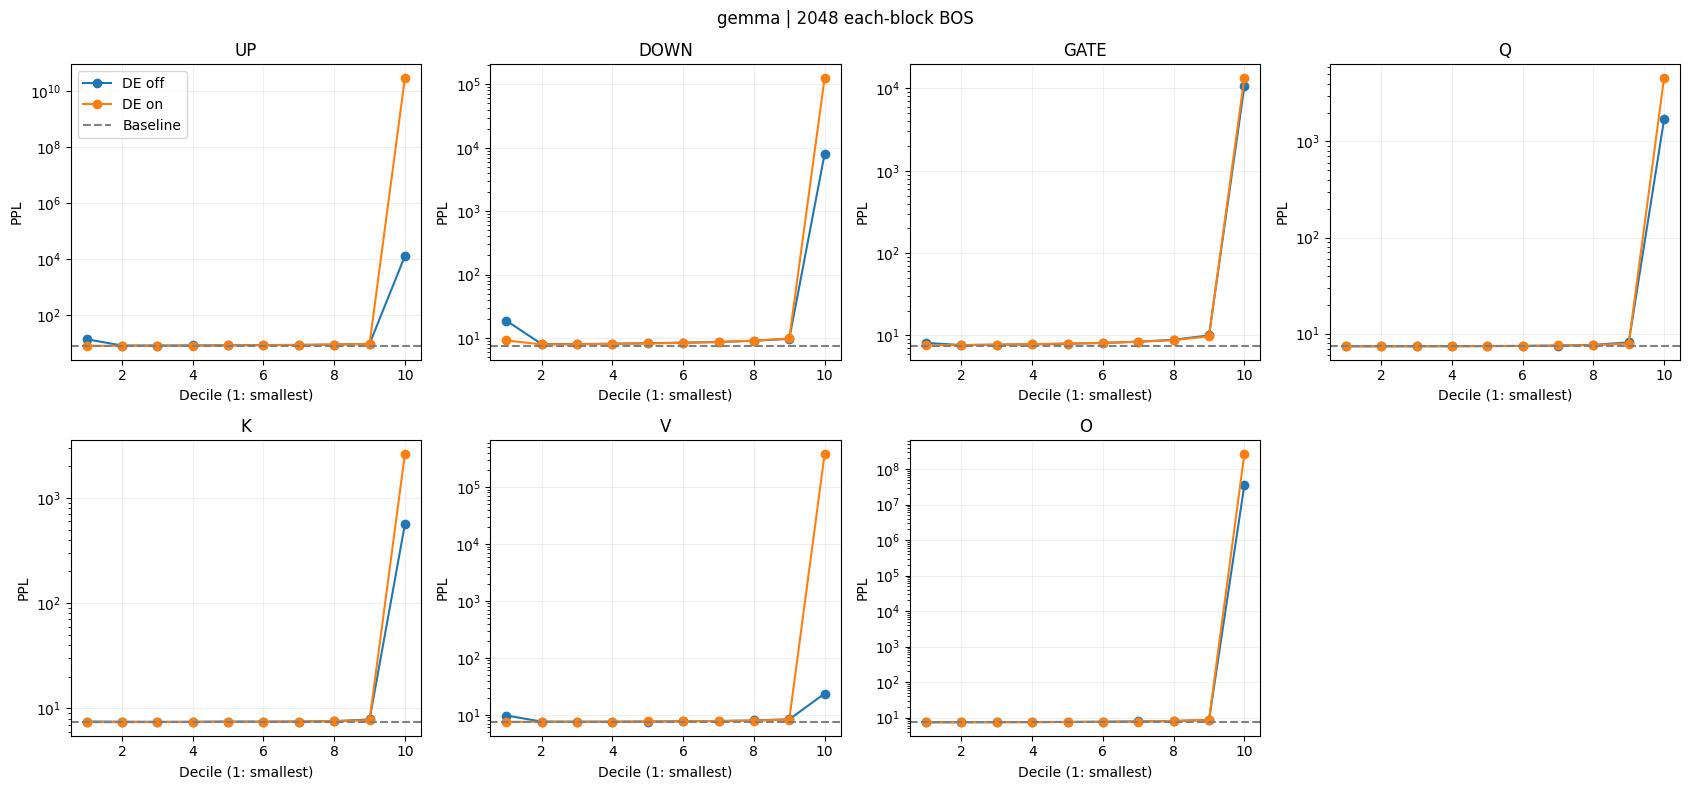

,id,kind,group,de,decile,seed,saved_parameters,reduction_model,parent_kind,requested,status,ppl
0,baseline,baseline,None,None,NaN,NaN,NaN,NaN,None,True,complete,7.388555
1,top50_fullKS__common_KS_order__de0,top50_fullKS,common_KS_order,False,NaN,NaN,153892352.0,0.039660,None,True,complete,104.904845
2,top50_fullKS__common_KS_order__de1,top50_fullKS,common_KS_order,True,NaN,NaN,151579648.0,0.039064,None,True,complete,16.884212
3,top50_bulkKS__common_bulkKS_order__de0,top50_bulkKS,common_bulkKS_order,False,NaN,NaN,171151872.0,0.044108,None,True,complete,31.636901
4,top50_bulkKS__common_bulkKS_order__de1,top50_bulkKS,common_bulkKS_order,True,NaN,NaN,169066496.0,0.043571,None,True,complete,14.424967
5,budget1__q_proj__de0,budget1,q_proj,False,NaN,NaN,38663168.0,0.009964,None,True,complete,7.719802
6,budget1__q_proj__de1,budget1,q_proj,True,NaN,NaN,38663168.0,0.009964,None,True,complete,7.629248
7,budget1__k_proj__de0,budget1,k_proj,False,NaN,NaN,38802432.0,0.010000,None,True,complete,9.707536
8,budget1__k_proj__de1,budget1,k_proj,True,NaN,NaN,38802432.0,0.010000,None,True,complete,8.295959
9,budget1__v_proj__de0,budget1,v_proj,False,NaN,NaN,38802432.0,0.010000,None,True,complete,443.218205


未完了・overflowは欠損として扱い、改善と解釈しないでください。


de,kind,group,decile,seed,parent_kind,PPL_DE_off,PPL_DE_on,delta_PPL_on_minus_off
0,budget1,down_proj,none,none,none,56.385075,13.044827,-43.340248
1,budget1,gate_proj,none,none,none,9.058665,8.440693,-0.617972
2,budget1,k_proj,none,none,none,9.707536,8.295959,-1.411577
3,budget1,o_proj,none,none,none,8.863300,8.047488,-0.815812
4,budget1,q_proj,none,none,none,7.719802,7.629248,-0.090553
...,...,...,...,...,...,...,...,...
76,decile,V,9.0,none,none,8.330393,8.270841,-0.059552
77,top50_bulkKS,common_bulkKS_order,none,none,none,31.636901,14.424967,-17.211934
78,top50_fullKS,common_KS_order,none,none,none,104.904845,16.884212,-88.020632
79,top50_lora,common_KS_order,none,42.0,top50_fullKS,8.284502,7.978162,-0.306341


In [9]:
RESULTS=status13(); display(RESULTS)
done=RESULTS[RESULTS.status=='complete'].copy()
if len(done):
    baseline=done.loc[done.kind=='baseline','ppl']
    if len(baseline):
        fig,axes=plt.subplots(2,4,figsize=(17,8))
        for ax,g in zip(axes.flat,ALL_GROUPS):
            for de,label in [(False,'DE off'),(True,'DE on')]:
                x=done[(done.kind=='decile')&(done.group==g)&(done.de==de)].set_index('decile').reindex(range(1,11))
                ax.plot(x.index,x.ppl,'-o',label=label)
            ax.axhline(float(baseline.iloc[0]),ls='--',color='gray',label='Baseline')
            ax.set(title=g,xlabel='Decile (1: smallest)',ylabel='PPL',yscale='log');ax.grid(alpha=.2)
        axes.flat[-1].axis('off');axes.flat[0].legend();fig.suptitle(MODEL_KEY+' | 2048 each-block BOS')
        fig.tight_layout();fig.savefig(evaluation_dir(OUTPUT)/'decile_ppl.pdf');plt.show()
    display(done[done.kind!='decile'])
print('未完了・overflowは欠損として扱い、改善と解釈しないでください。')

# DEの比較は同じkind・module・decile・seed・選択順序だけで対応付ける。
paired=done[done.kind!='baseline'].copy()
if len(paired):
    for c in ['group','decile','seed','parent_kind']:paired[c]=paired[c].fillna('none').astype(str)
    paired=paired.pivot(index=['kind','group','decile','seed','parent_kind'],columns='de',values='ppl').rename(columns={False:'PPL_DE_off',True:'PPL_DE_on'})
    if {'PPL_DE_off','PPL_DE_on'}<=set(paired):
        paired['delta_PPL_on_minus_off']=paired.PPL_DE_on-paired.PPL_DE_off
    paired=paired.reset_index();atomic_csv(evaluation_dir(OUTPUT)/'paired_ppl.csv',paired);display(paired)


In [10]:
if AUTO_DISCONNECT and RUN_EXPERIMENTS:
    pending = [
        j["id"] for j in PLAN
        if requested13(j) and complete13(j) is None
    ]

    if pending:
        raise RuntimeError(
            f"未完了の条件が {len(pending)} 件あるため切断しません。"
        )

    from google.colab import runtime
    print("全条件の保存を確認しました。ランタイムを解放します。", flush=True)
    runtime.unassign()
else:
    print("自動切断は無効です。接続を維持します。")

自動切断は無効です。接続を維持します。


In [11]:
from google.colab import runtime
print("全条件の保存を確認しました。ランタイムを解放します。", flush=True)
runtime.unassign()

全条件の保存を確認しました。ランタイムを解放します。
